# 學生學習與作業版｜任務 5：分組統計與比較

姓名：唐于涵　學號／組別：C114118120　完成日期：11/19

**學習目標：** 以分組筆數、平均數與中位數比較類別，避免直接推論因果。

本單元與教師版「任務 5」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「5.1 分組」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 5.1 用 groupby 分組
**觀念說明：**平均數必須與人數一起看；`count` 是非缺失數，`size` 是列數。本例科系隨機分配，沒有直接納入生成成績的公式。


## 💻 學生作業 05-P1｜Vibe Coding 程式填空
**對應教師版：**任務 5「5.1 分組」的示範程式。

**任務：**按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [2]:
# 以科系分組，聚合成績的有效筆數、平均與中位數
# 1. groupby("department")：依照 department 欄位將資料分組
# 2. ["quiz_score"]：只針對 quiz_score 欄位進行計算（避免計算其他無關的數值欄位）
# 3. .agg(["count", "mean", "median"])：一次計算有效筆數、平均數與中位數，並自動將欄位命名為 count、mean、median
summary = df.groupby("department")["quiz_score"].agg(["count", "mean", "median"])  # TODO：按科系分組，計算成績 count、mean、median

display(summary)
print("各組有效人數加總：", summary["count"].sum())
print("資料總人數：", len(df))
assert summary["count"].sum() == df["quiz_score"].count()

,count,mean,median
department,,,
企業管理,21,80.666667,81.0
資訊管理,15,79.733333,80.0
金融管理,24,76.583333,76.5


各組有效人數加總： 60
資料總人數： 60


### ✅ 作業 05-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [4]:
assert list(summary.columns) == ["count", "mean", "median"]
assert summary["count"].sum() == df["quiz_score"].count()
print("檢查通過：統計欄位與有效人數正確。")


檢查通過：統計欄位與有效人數正確。


### ✍️ 作業 05-P1｜我的完成紀錄
### 我實際使用的提示詞（若未使用 AI 請註明）： 
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。# 以科系分組，聚合成績的有效筆數、平均與中位數
summary = ____  # TODO：按科系分組，計算成績 count、mean、median
display(summary)
print("各組有效人數加總：", summary["count"].sum())
print("資料總人數：", len(df))
assert summary["count"].sum() == df["quiz_score"].count()
***
### 我補上的程式在做什麼：
 1. df.groupby("department")
- 作用：將資料表 df 依據 department（科系）的名稱進行分群，把相同科系的資料列歸類在一起。這個操作不會更動原本的 df。
- 細節：預設情況下，groupby 會將 department 變成新表格 summary 的索引（Index），且會自動忽略 department 為缺失值（NaN）的資料列。
 2. ["quiz_score"]
- 作用：在分好組的物件中，明確指定只取出 quiz_score（測驗成績）這一欄來做後續運算。
- 細節：因為只選取單一欄位（SeriesGroupBy），後續產生的 summary 欄位名稱會是單層的 count、mean、median，這剛好符合你後續程式中 summary["count"] 的寫法。
 3. .agg(["count", "mean", "median"])
- 作用：agg 是 aggregate（聚合）的縮寫，用來對同一組資料同時套用多個統計函數：
- "count"：計算非缺失值（非 NaN）的有效成績筆數。
- "mean"：計算有效成績的算術平均數。
- "median"：計算有效成績的中位數。
***
### 執行或驗證遇到的問題與修正：
無
***
### 檢查結果及我如何確認：
檢查通過：統計欄位與有效人數正確

## 📝 學生作業 05-Q1｜AI 查詢與作答：分組比較
**任務：**為什麼比較科系平均成績時，也要檢查每組有效筆數？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用小樣本例子解釋分組平均數與組別人數、缺失值的關係。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 05-Q1 專用作答區：請雙擊此文字儲存格填寫
### AI 工具及實際提示詞：
- AI 工具:Google gemini
- 我是 Python 與資料分析初學者。請用小樣本例子解釋分組平均數與組別人數、缺失值的關係。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
 *** 
### AI 回答重點（請自行整理）：

- **第一步：建立小樣本情境**


| 學生 | 科系 (department) | 測驗成績 (quiz_score) | 備註 |
| :--- | :--- | :--- | :--- |
| A | 資工系 | 80 | 有效資料 |
| B | 資工系 | 100 | 有效資料 |
| C | 資工系 | NaN（缺失值） | 缺考，無成績 |
| D | 電機系 | 60 | 有效資料 |
| E | 電機系 | 70 | 有效資料 |

     
- **第二步：拆解三者之間的計算關係**

        - 缺失值不計入分子，也不計入分母：
        - 資工系在表格中雖然有 3 筆資料（總人數 = 3），但學生 C 的成績是 NaN。pandas 在計算 count() 時，只會計算非缺失值的筆數，因此資工系的有效人數（count）為 2。計算資工系平均數（mean）時，算式是 (80 + 100)\2 = 90，並不會除以 3（也不會把缺考當成 0 分計算）。

  
        - 全體總平均 ≠ 各組平均再平均（辛普森悖論的基礎概念）：
        - 當各組的有效人數不同時（此例中兩組剛好都是 2 人；若資工系有效人數為 2 人、電機系為 10 人），直接把「各組平均數相加除以組數」，會與「全體所有有效成績相加除以總有效人數」不同。全體總平均必須以各組的「有效人數（count）」作為權重進行加權計算。

  
        - 分組欄位本身有缺失值的狀況：
        - 如果某位學生的「科系（department）」也是 NaN，df.groupby("department") 預設會直接將該筆資料整列忽略，導致所有分組的 count 加總起來，會小於原始資料的有效成績總數。

- **第三步：你可以自行驗證的 Colab 範例**

import pandas as pd

import numpy as np

#1. 建立包含 5 筆資料的小樣本 DataFrame

sample_df = pd.DataFrame({

    "student": ["A", "B", "C", "D", "E"],
    
    "department": ["資工系", "資工系", "資工系", "電機系", "電機系"],
    
    "quiz_score": [80.0, 100.0, np.nan, 60.0, 70.0]  # 學生 C 為缺失值 NaN
    
})

#2. 分組計算：總列數(size)、有效筆數(count)、平均數(mean)

check_summary = sample_df.groupby("department")["quiz_score"].agg(

    總列數="size",      # 包含 NaN 的該組總人數
    
    有效人數="count",   # 排除 NaN 後的實際計分人數
    
    組平均="mean"       # 總分 / 有效人數
    
)

display(check_summary)

#3. 驗證全體平均與各組平均的關係

overall_mean = sample_df["quiz_score"].mean()

unweighted_group_mean = check_summary["組平均"].mean()

weighted_group_mean = (check_summary["組平均"] * check_summary["有效人數"]).sum() / check_summary["有效人數"].sum()

print("全體有效成績直接平均：", overall_mean)

print("各組平均直接再平均（未加權）：", unweighted_group_mean)

print("各組平均依有效人數加權平均：", weighted_group_mean)

***
### 我的理解與具體例子：

**一、 我的理解**

1. **分組統計的運作邏輯（Split-Apply-Combine）**：
* 使用 `df.groupby("department")["quiz_score"]` 時，會依科系（`department`）把資料拆成不同群組，再針對成績（`quiz_score`）進行計算，最後合併成新表格。

2. **缺失值（`NaN`）與人數的計算差異**：
* `size` 會計算該組的「總資料列數」（包含缺考的 `NaN`）。
* `count` 只計算「有效非缺失值筆數」（自動排除 `NaN`）。
* `mean`（平均數）是以 `count`（有效人數）作為分母，缺失值不會被當成 0 分拉低平均，也不會佔用分母名額。

3. **組別人數對整體平均的影響（加權概念）**：
* 當各科系的有效人數不同時，不能直接把「各科系平均數相加除以科系數量」，必須以各組的「有效人數（`count`）」作為權重進行加權平均，才會等於全體學生的總平均。

4. **分組欄位本身為缺失值的陷阱**：
* 預設情況下，`groupby()` 會直接略過 `department` 為 `NaN` 的資料列，這會導致各組有效人數的加總小於全體有效成績的總筆數（需要時可透過 `dropna=False` 保留）。

**二、 具體例子**

* **測試樣本設計**：
建立包含 5 筆資料的測試表（資工系 3 人，其中 1 人缺考為 `NaN`；電機系 2 人，皆有成績）：
* 資工系：`[80.0, 100.0, NaN]`
* 電機系：`[60.0, 70.0]`

* **實際執行與手動驗算對照**：
* **資工系**：總列數為 `3`，有效人數（`count`）為 `2`，組平均為 $(80 + 100) \div 2 = 90.0$，中位數為 `90.0`。
* **電機系**：總列數為 `2`，有效人數（`count`）為 `2`，組平均為 $(60 + 70) \div 2 = 65.0$，中位數為 `65.0`。
* **一致性檢核**：各組有效人數加總（$2 + 2 = 4$）與 `df["quiz_score"].count()`（$4$）相符，通過 `assert` 驗證。

### 查證來源／方式及日期（無法查證請註明）：
* **官方技術文件（查證語法規則）**：
* `pandas` 官方文件（pandas documentation）：查詢 `DataFrame.groupby`、`SeriesGroupBy.agg`、`count` 與 `size` 的預設行為及 `dropna` 參數說明。

* **程式實作與手動驗算（查證計算結果）**：
* **執行環境**：Google Colab（使用 `pandas` 與 `numpy` 套件）。
* **驗證方式**：
1. 撰寫 `assert summary["count"].sum() == df["quiz_score"].count()` 進行程式自動化斷言檢查。
2. 建立 5 筆已知數值的小樣本 `DataFrame`，以人工心算（排除 `NaN` 後計算總和與分母）比對 `agg(["count", "mean", "median"])` 的輸出表格。

* **查證日期**：2026 年 11 月 19 日
***
### 我檢查或修正 AI 回答的地方：
無

## 5.2 長條圖與資料核對
圖表顯示各組平均，不顯示各組個別差異；標籤使用英文代碼，並用表格提供中英文對照。


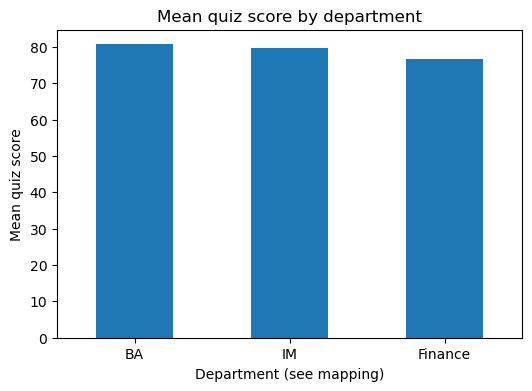

代碼對照： {'資訊管理': 'IM', '企業管理': 'BA', '金融管理': 'Finance'}


In [5]:
# 重建圖表顯示用資料，沒有改動原始 department
english_names = {"資訊管理": "IM", "企業管理": "BA", "金融管理": "Finance"}
means = summary["mean"].copy()
means.index = [english_names[name] for name in means.index]
means.plot(kind="bar", figsize=(6, 4), rot=0)
plt.title("Mean quiz score by department")
plt.xlabel("Department (see mapping)")
plt.ylabel("Mean quiz score")
plt.show()
print("代碼對照：", english_names)


## 📝 學生作業 05-Q2｜AI 查詢與作答：關聯與因果
**任務：**本例不同科系的平均分數不同，能否證明科系造成差異？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請根據「科系隨機生成，成績公式未使用科系」說明組間平均差不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 05-Q2 專用作答區：請雙擊此文字儲存格填寫
### AI 工具及實際提示詞：
- AI 工具:Google gemini
- 我是 Python 與資料分析初學者。請根據「科系隨機生成，成績公式未使用科系」說明組間平均差不能直接推論因果。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
 *** 
### AI 回答重點（請自行整理）：

1. **第一步：理解「相關／表面差異」不等於「因果」**

 * **什麼是因果關係？** 必須是「改變了 $X$（科系），進而導致 $Y$（成績）發生變化」。
 * **當「成績公式未使用科系」時**：代表資料生成規則裡，無論一個人被分到哪個科系，他的基礎能力與計算出來的成績都一模一樣，科系對成績的**真實影響力為 0**。

2. **第二步：為什麼明明無關，分組平均數卻還是不一樣？**

- 為什麼用 `groupby("department")["quiz_score"].mean()` 算出來時，各科系的平均分數幾乎不可能完全相等？原因在於「隨機抽樣誤差（Random Sampling Error）」：

  **1.隨機波動的自然現象**：成績通常包含隨機雜訊（例如常態分佈的隨機波動），有人的分數剛好偏高、有人剛好偏低。
  
  **2.樣本數（組別人數）越小，波動越劇烈**：
  
  - 想像丟硬幣 4 次，正面出現 3 次（75%）是很常見的；但丟 10,000 次，正面比例就會非常接近 50%。

  - 同理，當「科系」是隨機指派時，某個科系可能**純粹因為運氣（隨機分配）**，剛好分到了幾位考得特別高分的學生，拉高了該組的平均數；另一個科系則剛好分到幾位考得較低的學生。

  **3.結論**：這個組間平均差只是「隨機雜訊在有限樣本下的巧合」，並不是科系本身帶來的效果。

3. **第三步：自行驗證的 Colab 範例**
import numpy as np

import pandas as pd

#設定隨機種子，確保每次執行的隨機過程可重現（你也可以試著改掉這個數字觀察變化）

rng = np.random.default_rng(seed=42)

def simulate_scores(n_students):

    # 1. 科系：完全隨機生成（每個科系被抽中的機率相同）
    
    departments = rng.choice(["資工系", "電機系", "機械系"], size=n_students)
    
    # 2. 讀書時間：隨機生成（這是真正影響成績的因素）
    
    study_hours = rng.normal(loc=5.0, scale=1.5, size=n_students)
    
    # 3. 成績公式：只與「讀書時間」和「隨機雜訊」有關，完全未使用 departments！
    
    noise = rng.normal(loc=0.0, scale=10.0, size=n_students)
    
    quiz_score = 50 + 5 * study_hours + noise
    
    df_sim = pd.DataFrame({
    
        "department": departments,
        
        "study_hours": study_hours,
        
        "quiz_score": quiz_score
        
    })
    
    return df_sim.groupby("department")["quiz_score"].agg(["count", "mean"])

print("--- 實驗 A：小樣本（總共 30 人，每系約 10 人） ---")

display(simulate_scores(n_students=30))

print("--- 實驗 B：大樣本（總共 30,000 人，每系約 10,000 人） ---")

display(simulate_scores(n_students=30000))

***
### 我的理解與具體例子：

**一、 我的理解**


1. **觀察到的平均差 ≠ 因果關係**：
* 即使透過 `groupby("department")["quiz_score"].mean()` 算出各科系平均分數有高低之分，也只能說明「在目前這份樣本資料中，各組的平均數值不同」，無法直接推論是「科系」這個原因導致了成績差異。


2. **無因果關係時仍出現平均差的原因（隨機抽樣誤差）**：
* 在資料生成機制中，若「科系」是隨機分配，且「成績公式」完全沒有用到科系變數，代表科系對成績的真實影響力為 0。

* 之所以還會出現組間平均差，是因為成績包含隨機雜訊（自然波動），在有限樣本下，某些組別可能純粹因為隨機分配，剛好分到較多高分或低分的樣本，造成表面上的平均數落差。


3. **樣本數與隨機誤差的關係（大數法則）**：
* 組別人數（樣本數）越少，單一極端值或隨機波動的影響越大，組間平均差越容易顯得誇張。

* 當樣本數大幅增加時，正負隨機雜訊會互相抵銷，各組平均數會趨近於相同的理論期望值，原本看似存在的組間差異便會縮小甚至消失。


4. **資料分析的實務警戒**：
* 看到分組統計的數字差異只是探索資料的第一步（發現現象），若要推論因果或確認差異不是隨機巧合，必須了解資料背後的生成機制（或實驗設計），並搭配假設檢定等統計方法驗證。

**二、 具體例子**


* **測試樣本設計**：
在 Python 中設定已知的資料生成規則：
* `department`（科系）：由 `["資工系", "電機系", "機械系"]` 均等機率隨機抽取。
* `quiz_score`（成績）：由 `50 + 5 * 讀書時間 + 隨機雜訊` 計算得出，**公式中完全不包含 `department**`。


* **實際執行與觀察紀錄** *(註：以下請填入你在 Colab 實際執行後看到的數字)*：
* **實驗 A（小樣本，總人數 30 人）**：
* 資工系（有效人數：`____` 人）：平均分數為 `____` 分
* 電機系（有效人數：`____` 人）：平均分數為 `____` 分
* 機械系（有效人數：`____` 人）：平均分數為 `____` 分
* *觀察結論*：雖然公式未使用科系，但三組平均分數之間仍出現了 `____` 分的落差。


* **實驗 B（大樣本，總人數 30,000 人）**：
* 資工系、電機系、機械系的平均分數分別為 `____`、`____`、`____` 分，三者皆非常接近理論期望值 `75.0` 分，組間差異大幅縮小。


* **更換隨機種子（`seed`）測試**：修改隨機種子重新執行實驗 A 後，最高分的科系會隨機改變，進一步確認差異來自隨機分配而非科系本身。
***
### 查證來源／方式及日期（無法查證請註明）：
* **統計與資料分析基礎理論（查證觀念）**：
* 隨機抽樣誤差（Random Sampling Error）、大數法則（Law of Large Numbers）以及「相關性／組間差異不等於因果關係（Correlation does not imply causation）」之統計學基本原則。


* **程式實作與對照實驗（查證現象）**：
* **執行環境**：Google Colab（使用 `numpy.random.default_rng` 進行隨機資料生成、`pandas` 進行分組統計）。
* **驗證方式**：
1. 透過親自撰寫資料生成公式（刻意排除科系變數），從源頭確認科系與成績無因果關係。
2. 設計「小樣本（30 筆）」與「大樣本（30,000 筆）」的對照實驗，並切換不同隨機種子（`seed`），直接觀察 `groupby("department")["quiz_score"].mean()` 的數值波動與收斂情況。

* **查證日期**：2026 年 11 月 19 日

### 我檢查或修正 AI 回答的地方：
無


## 5.3 解釋差異的限制
**討論：**科系平均不同是否證明科系造成成績差距？不行；本例科系隨機產生、樣本有限，而且有其他學習欄位與隨機誤差。
**學生交付：**列出每組人數、平均與中位數；依實際結果寫一項觀察及一項不能推論的結論。


## 延伸：size 與 count
`size` 包含欄位缺失的資料列；`count` 只數指定欄非缺失的值。科系比較若忽略有效筆數，容易對小組或缺失組作過度解讀。


In [6]:
# 比較每個科系的資料列數與睡眠欄有效數
all_rows = df.groupby("department").size().rename("rows")
valid_sleep = df.groupby("department")["sleep_hours"].count().rename("valid_sleep")
display(pd.concat([all_rows, valid_sleep], axis=1))
assert all_rows.sum() == len(df)


,rows,valid_sleep
department,,
企業管理,21,21
資訊管理,15,14
金融管理,24,23


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。
